In [1]:
import pandas as pd

In [2]:
df_retail =pd.read_excel('C:\\Users\\HP\\OneDrive\\Desktop\\SQl practice\\Online Retail.xlsx')


In [3]:
df_retail.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
df_retail.shape


(541909, 8)

In [5]:
df_retail.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [6]:
df_retail.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
CustomerID_Null=df_retail[df_retail['CustomerID'].isnull()].copy()

In [8]:
CustomerID_Null.shape

(135080, 8)

In [9]:
CustomerID_Null.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [10]:
CustomerID_Null[(CustomerID_Null['Description'].isnull()) & (CustomerID_Null['UnitPrice']==0)].shape[0]

1454

In [11]:
df_retail[df_retail['Description'].isnull()]['Quantity'].describe()

count    1454.000000
mean       -9.359697
std       243.238758
min     -3667.000000
25%       -24.000000
50%        -3.000000
75%         4.000000
max      5568.000000
Name: Quantity, dtype: float64

In [12]:
CustomerID_Null[(CustomerID_Null['Quantity']<=0) &(CustomerID_Null['Description'].isnull())]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
...,...,...,...,...,...,...,...,...
517719,580087,84341B,NaN,-2,2011-12-01 14:27:00,0.0,NaN,United Kingdom
521333,580359,20775,NaN,-35,2011-12-02 16:11:00,0.0,NaN,United Kingdom
522160,580379,72225C,NaN,-144,2011-12-02 17:57:00,0.0,NaN,United Kingdom
522162,580381,21758,NaN,-9,2011-12-02 17:58:00,0.0,NaN,United Kingdom


In [13]:
df_retail[df_retail["Quantity"] < 0].shape[0]

10624

In [14]:
negative_qty = df_retail[
    df_retail["Quantity"] < 0
].copy()

negative_qty[
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "CustomerID"]
].head(10)

,InvoiceNo,Description,Quantity,UnitPrice,CustomerID
141,C536379,Discount,-1,27.50,14527.0
154,C536383,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,15311.0
235,C536391,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,17548.0
236,C536391,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,17548.0
237,C536391,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,17548.0
238,C536391,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,17548.0
239,C536391,CHICK GREY HOT WATER BOTTLE,-12,3.45,17548.0
240,C536391,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,17548.0
241,C536391,PLASTERS IN TIN SKULLS,-24,1.65,17548.0
939,C536506,JAM MAKING SET WITH JARS,-6,4.25,17897.0


In [15]:
negative_qty["InvoiceNo"].astype(str).str.startswith("C").value_counts()

InvoiceNo
True     9288
False    1336
Name: count, dtype: int64

In [16]:
negative_without_c =negative_qty[~negative_qty["InvoiceNo"].astype(str).str.startswith("C")].copy()

In [17]:
negative_without_c[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID"]
].head(10)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
2406,536589,21777,NaN,-10,0.0,NaN
4347,536764,84952C,NaN,-38,0.0,NaN
7188,536996,22712,NaN,-20,0.0,NaN
7189,536997,22028,NaN,-20,0.0,NaN
7190,536998,85067,NaN,-6,0.0,NaN
7192,537000,21414,NaN,-22,0.0,NaN
7193,537001,21653,NaN,-6,0.0,NaN
7195,537003,85126,NaN,-2,0.0,NaN
7196,537004,21814,NaN,-30,0.0,NaN
7197,537005,21692,NaN,-70,0.0,NaN


In [18]:
negative_without_c[
    ["Description", "UnitPrice", "CustomerID"]
].isnull().sum()

Description     862
UnitPrice         0
CustomerID     1336
dtype: int64

In [19]:
(negative_without_c["UnitPrice"] == 0).sum()

np.int64(1336)

In [20]:
negative_without_c[
    negative_without_c["Description"].notna()
][
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice"]
].head(15)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice
7313,537032,21275,?,-30,0.0
13217,537425,84968F,check,-20,0.0
13218,537426,84968E,check,-35,0.0
13264,537432,35833G,damages,-43,0.0
21338,538072,22423,faulty,-13,0.0
21518,538090,20956,?,-723,0.0
22296,538161,46000S,Dotcom sales,-100,0.0
22297,538162,46000M,Dotcom sales,-100,0.0
42564,540010,22501,reverse 21/5/10 adjustment,-100,0.0
42566,540012,22502,reverse 21/5/10 adjustment,-100,0.0


In [21]:
import numpy as np

conditions = [
    df_retail["InvoiceNo"].astype(str).str.startswith("C"),
    (df_retail["Quantity"] < 0) &
    (df_retail["UnitPrice"] == 0)
]

choices = [
    "Cancellation",
    "Nonstandard Adjustment"
]

df_retail["TransactionType"] = np.select(
    conditions,
    choices,
    default="Other - Pending Review"
)

In [22]:
df_retail["TransactionType"].value_counts()

TransactionType
Other - Pending Review    531285
Cancellation                9288
Nonstandard Adjustment      1336
Name: count, dtype: int64

In [23]:
df_retail

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,Other - Pending Review
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Other - Pending Review
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,Other - Pending Review
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Other - Pending Review
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,Other - Pending Review
...,...,...,...,...,...,...,...,...,...
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,Other - Pending Review
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,Other - Pending Review
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,Other - Pending Review
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,Other - Pending Review


In [24]:
df_retail[(df_retail['Quantity']>0) & (df_retail['UnitPrice']==0)].shape[0]
    

1179

In [25]:
zero_price_positive_qty = df_retail[
    (df_retail["Quantity"] > 0) &
    (df_retail["UnitPrice"] == 0)
].copy()

zero_price_positive_qty[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID"]
].head(15)

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
622,536414,22139,NaN,56,0.0,NaN
1970,536545,21134,NaN,1,0.0,NaN
1971,536546,22145,NaN,1,0.0,NaN
1972,536547,37509,NaN,1,0.0,NaN
1987,536549,85226A,NaN,1,0.0,NaN
1988,536550,85044,NaN,1,0.0,NaN
2024,536552,20950,NaN,1,0.0,NaN
2025,536553,37461,NaN,3,0.0,NaN
2026,536554,84670,NaN,23,0.0,NaN
4348,536765,84952C,NaN,19,0.0,NaN


In [26]:
zero_price_positive_qty.isna().sum()

InvoiceNo             0
StockCode             0
Description         592
Quantity              0
InvoiceDate           0
UnitPrice             0
CustomerID         1139
Country               0
TransactionType       0
dtype: int64

In [27]:
zero_price_positive_qty.shape[0]

1179

In [28]:
zero_price_positive_qty[zero_price_positive_qty['CustomerID'].isnull()].shape[0]

1139

In [29]:
zero_price_positive_qty_percentage=zero_price_positive_qty[zero_price_positive_qty['CustomerID'].isnull()].shape[0]/zero_price_positive_qty.shape[0]

In [30]:
zero_price_positive_qty[zero_price_positive_qty['Description'].isnull()].shape[0]/zero_price_positive_qty.shape[0]

0.5021204410517388

In [31]:
customerIDzero_price_positive_qty=zero_price_positive_qty[~zero_price_positive_qty['CustomerID'].isnull()]

In [32]:
customerIDzero_price_positive_qty.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
9302,537197,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05 14:02:00,0.0,12647.0,Germany,Other - Pending Review
33576,539263,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16 14:36:00,0.0,16560.0,United Kingdom,Other - Pending Review
40089,539722,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21 13:45:00,0.0,14911.0,EIRE,Other - Pending Review
47068,540372,22090,PAPER BUNTING RETROSPOT,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom,Other - Pending Review
47070,540372,22553,PLASTERS IN TIN SKULLS,24,2011-01-06 16:41:00,0.0,13081.0,United Kingdom,Other - Pending Review
56674,541109,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13 15:10:00,0.0,15107.0,United Kingdom,Other - Pending Review
86789,543599,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10 13:08:00,0.0,17560.0,United Kingdom,Other - Pending Review
130188,547417,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23 10:25:00,0.0,13239.0,United Kingdom,Other - Pending Review
139453,548318,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30 12:45:00,0.0,13113.0,United Kingdom,Other - Pending Review
145208,548871,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04 14:42:00,0.0,14410.0,United Kingdom,Other - Pending Review


In [33]:
CustomerIDZeroPrice=customerIDzero_price_positive_qty[["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "CustomerID"]].copy()

In [34]:
CustomerIDZeroPrice['CustomerID'].nunique()

31

In [35]:
CustomerIDZeroPrice['InvoiceNo'].nunique()


34

In [36]:
CustomerIDZeroPrice['CustomerID'].value_counts().head(5)

CustomerID
13081.0    4
14646.0    4
14911.0    2
12415.0    2
13985.0    2
Name: count, dtype: int64

In [37]:
df_retail[df_retail['UnitPrice']<0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,Other - Pending Review
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,Other - Pending Review


In [38]:
df_retail[df_retail['UnitPrice']==11062.06]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,Other - Pending Review


In [39]:
df_retail[df_retail['InvoiceNo'].astype(str).str.startswith('A')]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,Other - Pending Review
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,Other - Pending Review
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,Other - Pending Review


In [40]:
df_retail[df_retail['Description']=='Adjust bad debt']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,Other - Pending Review
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,Other - Pending Review
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,Other - Pending Review


In [41]:
import numpy as np

conditions = [
    df_retail["InvoiceNo"].astype(str).str.startswith("C"),
    (df_retail["Quantity"] < 0) &
    (df_retail["UnitPrice"] == 0),
    df_retail["InvoiceNo"].astype(str).str.startswith("A")
]

choices = [
    "Cancellation",
    "Nonstandard Adjustment",
    "Adjust bad debt"
]

df_retail["TransactionType"] = np.select(
    conditions,
    choices,
    default="Other - Pending Review"
)

In [42]:
df_retail['TransactionType'].value_counts()

TransactionType
Other - Pending Review    531282
Cancellation                9288
Nonstandard Adjustment      1336
Adjust bad debt                3
Name: count, dtype: int64

In [43]:

   df_retail['TransactionType'].info()

<class 'pandas.Series'>
RangeIndex: 541909 entries, 0 to 541908
Series name: TransactionType
Non-Null Count   Dtype
--------------   -----
541909 non-null  str  
dtypes: str(1)
memory usage: 15.4 MB


In [44]:
df_pending_review=df_retail[df_retail['TransactionType']== 'Other - Pending Review'].copy()

In [45]:
df_pending_review[df_pending_review['UnitPrice']==0].shape[0]

1179

In [46]:
df_pending_review.isna().sum()

InvoiceNo               0
StockCode               0
Description           592
Quantity                0
InvoiceDate             0
UnitPrice               0
CustomerID         133358
Country                 0
TransactionType         0
dtype: int64

In [47]:
import numpy as np

conditions = [
    df_retail["InvoiceNo"].astype(str).str.startswith("C"),
    (df_retail["Quantity"] < 0) &
    (df_retail["UnitPrice"] == 0),
    df_retail["InvoiceNo"].astype(str).str.startswith("A"),
    (df_retail['UnitPrice']==0) &(df_retail['Quantity']>0)
    
]

choices = [
    "Cancellation",
    "Nonstandard Adjustment",
    "Adjust bad debt",
    'Zero Price Transaction'
]

df_retail["TransactionType"] = np.select(
    conditions,
    choices,
    default="Other - Pending Review"
)

In [48]:
df_retail[df_retail['TransactionType']=='Zero Price Transaction'].shape[0]

1179

In [49]:
df_retail[(df_retail['UnitPrice']==0) &(df_retail['Quantity']>0)].shape[0]

1179

In [50]:
df_retail['TransactionType'].value_counts()

TransactionType
Other - Pending Review    530103
Cancellation                9288
Nonstandard Adjustment      1336
Zero Price Transaction      1179
Adjust bad debt                3
Name: count, dtype: int64

In [51]:
duplicate_dataset=df_retail[df_retail.duplicated(keep=False)].copy()

In [52]:
duplicate_percentage =df_retail[df_retail.duplicated()].shape[0]/df_retail.shape[0]

In [53]:
print(f' {100*duplicate_percentage:.2f} %')

 0.97 %


In [54]:
duplicate_dataset.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,Other - Pending Review
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,Other - Pending Review
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,Other - Pending Review
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,Other - Pending Review
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,Other - Pending Review
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,Other - Pending Review
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,Other - Pending Review
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,Other - Pending Review
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,Other - Pending Review
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom,Other - Pending Review


In [55]:
df_retail[df_retail.duplicated(keep =False)].copy()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom,Other - Pending Review
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom,Other - Pending Review
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,Other - Pending Review
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom,Other - Pending Review
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom,Other - Pending Review
...,...,...,...,...,...,...,...,...,...
541675,581538,22068,BLACK PIRATE TREASURE CHEST,1,2011-12-09 11:34:00,0.39,14446.0,United Kingdom,Other - Pending Review
541689,581538,23318,BOX OF 6 MINI VINTAGE CRACKERS,1,2011-12-09 11:34:00,2.49,14446.0,United Kingdom,Other - Pending Review
541692,581538,22992,REVOLVER WOODEN RULER,1,2011-12-09 11:34:00,1.95,14446.0,United Kingdom,Other - Pending Review
541699,581538,22694,WICKER STAR,1,2011-12-09 11:34:00,2.10,14446.0,United Kingdom,Other - Pending Review


In [56]:
df_retail[df_retail.duplicated(keep =False)]['InvoiceNo'].nunique()

1933

In [57]:
df_retail[df_retail.duplicated(keep =False)]['InvoiceNo'].value_counts().head(10)

InvoiceNo
547651    57
579458    53
577482    52
572103    50
574481    49
552285    48
537781    47
555524    40
569897    40
575117    40
Name: count, dtype: int64

In [58]:
df_retail[df_retail['InvoiceNo']==547651]['StockCode'].nunique()

80

In [59]:
duplicate_dataset[duplicate_dataset['InvoiceNo']==547651]['StockCode'].value_counts()

StockCode
22249     4
22293     3
22291     3
22292     3
82613A    2
82613B    2
82613C    2
82613D    2
22084     2
85038     2
21389     2
22287     2
22285     2
85203     2
85014B    2
22553     2
22554     2
22551     2
22555     2
22556     2
15056P    2
84457     2
22248     2
22288     2
22595     2
22431     2
Name: count, dtype: int64

In [60]:
duplicate_dataset[(duplicate_dataset['InvoiceNo']==547651) & (duplicate_dataset['StockCode']==22249)]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
131985,547651,22249,DECORATION WHITE CHICK MAGIC GARDEN,1,2011-03-24 12:11:00,0.85,16904.0,United Kingdom,Other - Pending Review
131986,547651,22249,DECORATION WHITE CHICK MAGIC GARDEN,1,2011-03-24 12:11:00,0.85,16904.0,United Kingdom,Other - Pending Review
131988,547651,22249,DECORATION WHITE CHICK MAGIC GARDEN,1,2011-03-24 12:11:00,0.85,16904.0,United Kingdom,Other - Pending Review
131996,547651,22249,DECORATION WHITE CHICK MAGIC GARDEN,1,2011-03-24 12:11:00,0.85,16904.0,United Kingdom,Other - Pending Review


In [61]:
duplicate=df_retail[df_retail.duplicated]

In [62]:
duplicate['TransactionType'].value_counts()

TransactionType
Other - Pending Review    5226
Cancellation                37
Zero Price Transaction       5
Name: count, dtype: int64

In [63]:
duplicate['Revenue'] =duplicate['UnitPrice'] * duplicate['Quantity']

In [64]:
print(duplicate[duplicate['TransactionType'] =='Other - Pending Review']['Revenue'].sum())

24573.74


In [65]:
df_retail['Revenue'] =df_retail['UnitPrice'] * df_retail['Quantity']

In [66]:
df_retail[df_retail['TransactionType']=='Other - Pending Review']['Revenue'].sum().round(2)

np.float64(10655622.48)

In [67]:
percentage = duplicate[duplicate['TransactionType'] =='Other - Pending Review']['Revenue'].sum()/df_retail[df_retail['TransactionType']=='Other - Pending Review']['Revenue'].sum()

In [68]:
print(f'{100* percentage:.2f}%')

0.23%


In [69]:
df_Pending_Review=df_retail[df_retail['TransactionType']=='Other - Pending Review'].copy()

In [70]:
df_Pending_Review[(df_Pending_Review['Quantity']==0 )|(df_Pending_Review['UnitPrice']==0)].shape[0]

0

In [71]:
df_Pending_Review[df_Pending_Review['CustomerID'].isnull()].shape[0]

132219

In [72]:
df_Pending_Review.shape[0]

530103

In [73]:
Percentage_NUll_Id=df_Pending_Review[df_Pending_Review['CustomerID'].isnull()].shape[0]/df_Pending_Review.shape[0]

In [74]:
print(f'{100*Percentage_NUll_Id:.2f}%')

24.94%


In [75]:
df_Pending_Review[df_Pending_Review['Description'].isnull()].shape[0]

0

In [76]:
df_Pending_Review[df_Pending_Review['StockCode'].isnull()].shape[0]

0

In [77]:
#top 15 frequently sold  products
df_Pending_Review['StockCode'].value_counts().head(15)

StockCode
85123A    2265
85099B    2112
22423     2017
47566     1706
20725     1595
84879     1489
22197     1426
22720     1399
21212     1370
20727     1328
22383     1326
22457     1263
23203     1249
22386     1238
22469     1226
Name: count, dtype: int64

In [78]:
#best selling products by quantity
df_Pending_Review.groupby('StockCode')['Quantity'].sum().sort_values(ascending =False).head(10)

StockCode
23843     80995
23166     78033
22197     56921
84077     55047
85099B    48474
85123A    37660
84879     36461
21212     36419
23084     30788
22492     26633
Name: Quantity, dtype: int64

In [79]:
#Investigating transaction 23843
df_Pending_Review[df_Pending_Review['StockCode']==23843]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,Other - Pending Review,168469.6


In [80]:
df_Pending_Review[df_Pending_Review['CustomerID']==16446]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,Revenue
194354,553573,22980,PANTRY SCRUBBING BRUSH,1,2011-05-18 09:52:00,1.65,16446.0,United Kingdom,Other - Pending Review,1.65
194355,553573,22982,PANTRY PASTRY BRUSH,1,2011-05-18 09:52:00,1.25,16446.0,United Kingdom,Other - Pending Review,1.25
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,Other - Pending Review,168469.60


In [81]:
#investigating whether the highest transaction was cancelled
df_retail[df_retail['CustomerID']==16446]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,Revenue
194354,553573,22980,PANTRY SCRUBBING BRUSH,1,2011-05-18 09:52:00,1.65,16446.0,United Kingdom,Other - Pending Review,1.65
194355,553573,22982,PANTRY PASTRY BRUSH,1,2011-05-18 09:52:00,1.25,16446.0,United Kingdom,Other - Pending Review,1.25
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,Other - Pending Review,168469.60
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,Cancellation,-168469.60


In [82]:
df_retail[df_retail['StockCode']==23843]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,Other - Pending Review,168469.6
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom,Cancellation,-168469.6


In [83]:
df_retail[df_retail['TransactionType'] =='Cancellation']['Revenue'].sum()


np.float64(-896812.49)

In [84]:
df_retail['Revenue'].sum()

np.float64(9747747.934)

In [85]:
df_retail[(df_retail['TransactionType'] =='Cancellation')|(df_retail['TransactionType'] =='Other - Pending Review')]['Revenue'].sum()

np.float64(9758809.993999999)

In [86]:
Retail_ith_cancellation=df_retail[(df_retail['TransactionType'] =='Cancellation')|(df_retail['TransactionType'] =='Other - Pending Review')]

In [87]:
Retail_ith_cancellation['Quantity'].sum()

np.int64(5310801)

In [88]:
#top ten products with the highest quantity sold
Retail_ith_cancellation.groupby('StockCode')['Quantity'].sum().sort_values(ascending =False).head(10)
                                                                    

StockCode
22197     56450
84077     53847
85099B    47359
84879     36381
21212     36039
85123A    35082
23084     30680
22492     26437
22616     26111
21977     24753
Name: Quantity, dtype: int64

In [89]:
#top ten products by 10 products by net revenue
Retail_ith_cancellation.groupby('StockCode')['Quantity'].sum().sort_values(ascending =False).head(10)

StockCode
22197     56450
84077     53847
85099B    47359
84879     36381
21212     36039
85123A    35082
23084     30680
22492     26437
22616     26111
21977     24753
Name: Quantity, dtype: int64

In [90]:
Retail_ith_cancellation.groupby('StockCode')['Revenue'].sum().sort_values(ascending =False).head(10)

StockCode
DOT       206245.48
22423     164762.19
47566      98302.98
85123A     97894.50
85099B     92356.03
23084      66756.59
POST       66230.64
22086      63791.94
84879      58959.73
79321      53768.06
Name: Revenue, dtype: float64

In [91]:
Stock_code_DOT = Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='DOT']

In [92]:
Stock_code_DOT.shape[0]

707

In [93]:
Stock_code_DOT['Description'].head(5)

1814    DOTCOM POSTAGE
3041    DOTCOM POSTAGE
5450    DOTCOM POSTAGE
5545    DOTCOM POSTAGE
5685    DOTCOM POSTAGE
Name: Description, dtype: object

In [94]:
Stock_code_DOT['Revenue'].sum()

np.float64(206245.47999999998)

In [95]:
Stock_code_POST = Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='POST']

In [96]:
Stock_code_POST.shape[0]

1252

In [97]:
Stock_code_POST['Description'].head(5)

45      POSTAGE
386     POSTAGE
1123    POSTAGE
5073    POSTAGE
5258    POSTAGE
Name: Description, dtype: object

In [98]:
Stock_code_POST['Revenue'].sum()

np.float64(66230.64)

In [99]:
Retail_ith_cancellation.loc[
    Retail_ith_cancellation['StockCode']
    .astype(str)
    .str.match(r'^[A-Za-z]'),
    'StockCode'
].unique()

array(['POST', 'D', 'C2', 'DOT', 'M', 'BANK CHARGES', 'S', 'AMAZONFEE',
       'DCGS0076', 'DCGS0003', 'gift_0001_40', 'DCGS0070', 'm',
       'gift_0001_50', 'gift_0001_30', 'gift_0001_20', 'DCGS0069',
       'DCGSSBOY', 'DCGSSGIRL', 'gift_0001_10', 'PADS', 'DCGS0004',
       'CRUK'], dtype=object)

In [100]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='BANK CHARGES'].shape[0]

37

In [101]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='BANK CHARGES']['Description'].head(5)

4406     Bank Charges
14435    Bank Charges
28992    Bank Charges
62508    Bank Charges
64573    Bank Charges
Name: Description, dtype: object

In [102]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='BANK CHARGES']['Revenue'].sum()

np.float64(-7175.639000000001)

In [103]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='D'].shape[0]

77

In [104]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='D']['Description'].head(5)

141      Discount
9038     Discount
14498    Discount
19392    Discount
31134    Discount
Name: Description, dtype: object

In [105]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='D']['Revenue'].sum()

np.float64(-5696.219999999999)

In [106]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='C2'].shape[0]

143

In [107]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='C2']['Description'].head(5)

1423     CARRIAGE
12119    CARRIAGE
12452    CARRIAGE
19975    CARRIAGE
20016    CARRIAGE
Name: Description, dtype: object

In [108]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='C2']['Revenue'].sum()

np.float64(6986.0)

In [109]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='M'].shape[0]

565

In [110]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='M']['Description'].head(5)

2239    Manual
2250    Manual
5684    Manual
6798    Manual
7976    Manual
Name: Description, dtype: object

In [111]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='M']['Revenue'].sum()

np.float64(-68674.19)

In [112]:
M_transaction = Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='M'].copy()

In [113]:
M_transaction[M_transaction['UnitPrice']>0].shape[0]

565

In [114]:
M_transaction[M_transaction['Revenue']<0]['Revenue'].sum()

np.float64(-146784.46)

In [115]:
M_transaction[M_transaction['Revenue']>0]['Revenue'].sum()

np.float64(78110.26999999999)

In [116]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='AMAZONFEE'].shape[0]

34

In [117]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='AMAZONFEE']['Description'].head(5)

14514    AMAZON FEE
15016    AMAZON FEE
15017    AMAZON FEE
16232    AMAZON FEE
16313    AMAZON FEE
Name: Description, dtype: object

In [118]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='AMAZONFEE']['Revenue'].sum()

np.float64(-221520.5)

In [119]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='S'].shape[0]

63

In [120]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='S']['Description'].head(5)

14436    SAMPLES
14437    SAMPLES
96680    SAMPLES
96681    SAMPLES
96682    SAMPLES
Name: Description, dtype: object

In [121]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='S']['Revenue'].sum()

np.float64(-3049.39)

In [122]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode'].astype(str).str.startswith('gift_')].shape[0]

31

In [123]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode'].astype(str).str.startswith('gift_')]['StockCode'].unique()

array(['gift_0001_40', 'gift_0001_50', 'gift_0001_30', 'gift_0001_20',
       'gift_0001_10'], dtype=object)

In [124]:
Stock_gift=Retail_ith_cancellation[Retail_ith_cancellation['StockCode'].astype(str).str.startswith('gift_')][['StockCode','Description']].copy()

In [125]:
Stock_gift.groupby("StockCode")['Description'].count()

StockCode
gift_0001_10    8
gift_0001_20    9
gift_0001_30    7
gift_0001_40    3
gift_0001_50    4
Name: Description, dtype: int64

In [126]:
Stock_gift['Description'].unique()

array(['Dotcomgiftshop Gift Voucher £40.00',
       'Dotcomgiftshop Gift Voucher £50.00',
       'Dotcomgiftshop Gift Voucher £30.00',
       'Dotcomgiftshop Gift Voucher £20.00',
       'Dotcomgiftshop Gift Voucher £10.00'], dtype=object)

In [127]:
Stock_gift.drop_duplicates()

,StockCode,Description
38248,gift_0001_40,Dotcomgiftshop Gift Voucher £40.00
42057,gift_0001_50,Dotcomgiftshop Gift Voucher £50.00
44725,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00
44794,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00
112442,gift_0001_10,Dotcomgiftshop Gift Voucher £10.00


In [128]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode'].astype(str).str.startswith('gift_')]['Revenue'].sum()

np.float64(685.8100000000001)

In [129]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='PADS'].shape[0]

3

In [130]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='PADS']['Description']

157195    PADS TO MATCH ALL CUSHIONS
279045    PADS TO MATCH ALL CUSHIONS
359871    PADS TO MATCH ALL CUSHIONS
Name: Description, dtype: object

In [131]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='PADS']['Revenue'].sum()

np.float64(0.003)

In [132]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='PADS']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,Revenue
157195,550193,PADS,PADS TO MATCH ALL CUSHIONS,1,2011-04-15 09:27:00,0.001,13952.0,United Kingdom,Other - Pending Review,0.001
279045,561226,PADS,PADS TO MATCH ALL CUSHIONS,1,2011-07-26 10:13:00,0.001,15618.0,United Kingdom,Other - Pending Review,0.001
359871,568200,PADS,PADS TO MATCH ALL CUSHIONS,1,2011-09-25 14:58:00,0.001,16198.0,United Kingdom,Other - Pending Review,0.001


In [133]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='CRUK'].shape[0]

16

In [134]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='CRUK']['Description'].head(5)

317508    CRUK Commission
324023    CRUK Commission
333779    CRUK Commission
338848    CRUK Commission
351003    CRUK Commission
Name: Description, dtype: object

In [135]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='CRUK']['Revenue'].sum()

np.float64(-7933.43)

In [136]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode'].astype(str).str.startswith('DCG')].shape[0]

33

In [137]:
DCS_df=Retail_ith_cancellation[Retail_ith_cancellation['StockCode'].astype(str).str.startswith('DCG')][['StockCode','Description']].copy()

In [138]:
DCS_df.drop_duplicates()

,StockCode,Description
21326,DCGS0076,SUNJAR LED NIGHT NIGHT LIGHT
24906,DCGS0003,BOXED GLASS ASHTRAY
40052,DCGS0070,CAMOUFLAGE DOG COLLAR
75053,DCGS0069,OOH LA LA DOGS COLLAR
84016,DCGSSBOY,BOYS PARTY BAG
84017,DCGSSGIRL,GIRLS PARTY BAG
170783,DCGS0004,HAYNES CAMPER SHOULDER BAG


In [139]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode'].astype(str).str.startswith('DCG')]['Revenue'].sum()

np.float64(398.45)

In [140]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode']=='m']

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,Revenue
40383,539736,m,Manual,1,2010-12-21 15:18:00,2.55,NaN,United Kingdom,Other - Pending Review,2.55


In [141]:
Retail_ith_cancellation['StockCode_Clean'] =Retail_ith_cancellation['StockCode'].replace('m','M')

In [142]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean']=='m'].shape[0]

0

In [143]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean']=='M']['Revenue'].sum()

np.float64(-68671.64)

In [144]:
Retail_ith_cancellation.loc[
    Retail_ith_cancellation['StockCode']
    .astype(str)
    .str.match(r'^[A-Za-z]'),
    'StockCode'
].unique()

array(['POST', 'D', 'C2', 'DOT', 'M', 'BANK CHARGES', 'S', 'AMAZONFEE',
       'DCGS0076', 'DCGS0003', 'gift_0001_40', 'DCGS0070', 'm',
       'gift_0001_50', 'gift_0001_30', 'gift_0001_20', 'DCGS0069',
       'DCGSSBOY', 'DCGSSGIRL', 'gift_0001_10', 'PADS', 'DCGS0004',
       'CRUK'], dtype=object)

In [145]:
Retail_ith_cancellation.loc[
    Retail_ith_cancellation['StockCode_Clean']
    .astype(str)
    .str.match(r'^[A-Za-z]'),
    'StockCode_Clean'
].unique()

array(['POST', 'D', 'C2', 'DOT', 'M', 'BANK CHARGES', 'S', 'AMAZONFEE',
       'DCGS0076', 'DCGS0003', 'gift_0001_40', 'DCGS0070', 'gift_0001_50',
       'gift_0001_30', 'gift_0001_20', 'DCGS0069', 'DCGSSBOY',
       'DCGSSGIRL', 'gift_0001_10', 'PADS', 'DCGS0004', 'CRUK'],
      dtype=object)

In [146]:
Retail_ith_cancellation["Revenue"].sum()

np.float64(9758809.993999999)

In [147]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(['POST', 'DOT', 'C2'])]['Revenue'].sum()

np.float64(279462.12)

In [148]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(['BANK CHARGES','AMAZONFEE','CRUK'])]['Revenue'].sum()

np.float64(-236629.56900000002)

In [149]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean']=='D']['Revenue'].sum()

np.float64(-5696.219999999999)

In [150]:
six_categories =['POST', 'DOT', 'C2','BANK CHARGES','AMAZONFEE','CRUK','D','M','S','gift_0001_10','gift_0001_20','gift_0001_30', 'gift_0001_40','gift_0001_50' ]

In [151]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(six_categories)]['Revenue'].sum()

np.float64(-33898.88900000001)

In [152]:
Retail_ith_cancellation[~Retail_ith_cancellation['StockCode_Clean'].isin(six_categories)]['Revenue'].sum()

np.float64(9792708.883)

In [153]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(six_categories)].shape[0]

2926

In [154]:
Retail_ith_cancellation[~Retail_ith_cancellation['StockCode_Clean'].isin(six_categories)].shape[0]

536465

In [155]:
Retail_ith_cancellation.shape[0]

539391

In [156]:
percentage=Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(six_categories)].shape[0]/Retail_ith_cancellation.shape[0]

In [157]:
print(f"{100*percentage:.2f} %")

0.54 %


In [158]:
Percentage=Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(six_categories)]['Revenue'].sum()/Retail_ith_cancellation['Revenue'].sum()

In [159]:
print(f"{100*Percentage:.2f} %")

-0.35 %


In [160]:
shipping=Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(['POST', 'DOT', 'C2'])]['Revenue'].sum()/Retail_ith_cancellation['Revenue'].sum()

In [161]:
print(f"shipping = {100*shipping:.2f} %")

shipping = 2.86 %


In [162]:
abs(2.86)

2.86

In [163]:
Financial_charges=Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(['BANK CHARGES','AMAZONFEE','CRUK'])]['Revenue'].sum()/Retail_ith_cancellation['Revenue'].sum()

In [164]:
print(f"Financial_charges = {100*Financial_charges:.2f} %")

Financial_charges = -2.42 %


In [165]:
gift=Retail_ith_cancellation[Retail_ith_cancellation['StockCode'].astype(str).str.startswith('gift_')]['Revenue'].sum()/Retail_ith_cancellation['Revenue'].sum()

In [166]:
print(f"gift = {100*gift:.2f} %")

gift = 0.01 %


In [167]:
Discount=Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean']=='D']['Revenue'].sum()/Retail_ith_cancellation['Revenue'].sum()

In [168]:
print(f"Discount = {100*Discount:.2f} %")

Discount = -0.06 %


In [169]:
Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean']=='D']['Revenue'].sum()

np.float64(-5696.219999999999)

In [170]:
Sample=Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean']=='S']['Revenue'].sum()/Retail_ith_cancellation['Revenue'].sum()

In [171]:
print(f"Sample = {100*Sample:.2f} %")

Sample = -0.03 %


In [172]:
Manual=Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean']=='M']['Revenue'].sum()/Retail_ith_cancellation['Revenue'].sum()

In [173]:
print(f"Manual = {100*Manual:.2f} %")

Manual = -0.70 %


In [174]:
Top3_categories =['POST', 'DOT', 'C2','BANK CHARGES','AMAZONFEE','CRUK','M' ]

In [175]:
Percent=abs(Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(Top3_categories)]['Revenue']).sum()/abs(Retail_ith_cancellation[Retail_ith_cancellation['StockCode_Clean'].isin(six_categories)]['Revenue']).sum()


In [176]:
print(f'{100* Percent:.2f}%')

98.81%


In [177]:
Retail_ith_cancellation['Month'] = Retail_ith_cancellation['InvoiceDate'].dt.month

In [178]:
Retail_ith_cancellation['Year'] = Retail_ith_cancellation['InvoiceDate'].dt.year

Customer-level analysis was restricted to transactions with valid CustomerIDs to ensure that purchases could be attributed to identifiable customers. Transactions without CustomerIDs were retained for overall revenue analysis.

In [179]:
Retail_ith_cancellation.groupby('Month')['Revenue'].sum()

Month
1      560000.260
2      498062.650
3      683267.080
4      493207.121
5      723333.510
6      691123.120
7      681300.111
8      693742.570
9     1019687.622
10    1070704.670
11    1461756.250
12    1182625.030
Name: Revenue, dtype: float64

In [180]:
Retail_ith_cancellation.groupby(['Year','Month'])['Revenue'].sum()

Year  Month
2010  12        748957.020
2011  1         560000.260
      2         498062.650
      3         683267.080
      4         493207.121
      5         723333.510
      6         691123.120
      7         681300.111
      8         693742.570
      9        1019687.622
      10       1070704.670
      11       1461756.250
      12        433668.010
Name: Revenue, dtype: float64

In [181]:
# First transaction date
Retail_ith_cancellation['InvoiceDate'].min()



Timestamp('2010-12-01 08:26:00')

In [182]:
# Last transaction date
Retail_ith_cancellation['InvoiceDate'].max()


Timestamp('2011-12-09 12:50:00')

In [183]:
data_2011=Retail_ith_cancellation[Retail_ith_cancellation['Year']==2011]

In [184]:
data_2011_grouped=data_2011.groupby('Month')['Revenue'].sum()

In [185]:
import matplotlib.pyplot as plt

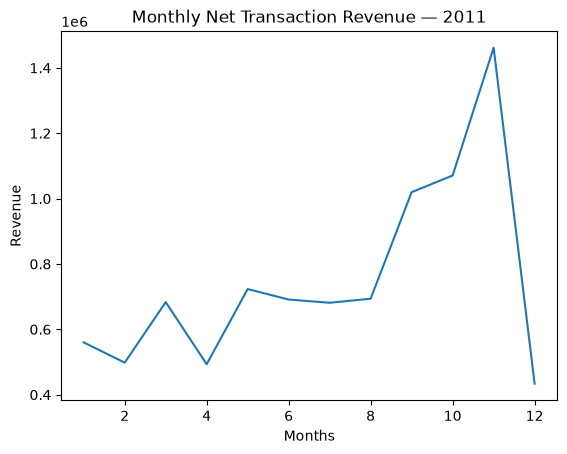

In [186]:
data_2011_grouped.plot(kind='line')
plt.xlabel('Months')
plt.ylabel('Revenue')
plt.title('Monthly Net Transaction Revenue — 2011')
plt.savefig(r'C:\Users\HP\OneDrive\Desktop\portfolios\Lineplot1')

plt.show()

In [187]:
Retail_ith_cancellation_Mech=Retail_ith_cancellation[~Retail_ith_cancellation['StockCode_Clean'].isin(six_categories)].copy()

In [188]:
top_10 = Retail_ith_cancellation_Mech.groupby(['StockCode_Clean','Description'])['Revenue'].sum().sort_values(ascending = False)

In [189]:
top_10 =top_10.head(10)

In [190]:
top_10

StockCode_Clean  Description                       
22423            REGENCY CAKESTAND 3 TIER              164762.19
47566            PARTY BUNTING                          98302.98
85123A           WHITE HANGING HEART T-LIGHT HOLDER     97715.99
85099B           JUMBO BAG RED RETROSPOT                92356.03
23084            RABBIT NIGHT LIGHT                     66756.59
22086            PAPER CHAIN KIT 50'S CHRISTMAS         63791.94
84879            ASSORTED COLOUR BIRD ORNAMENT          58959.73
79321            CHILLI LIGHTS                          53768.06
23298            SPOTTY BUNTING                         42065.32
22386            JUMBO BAG PINK POLKADOT                41619.66
Name: Revenue, dtype: float64

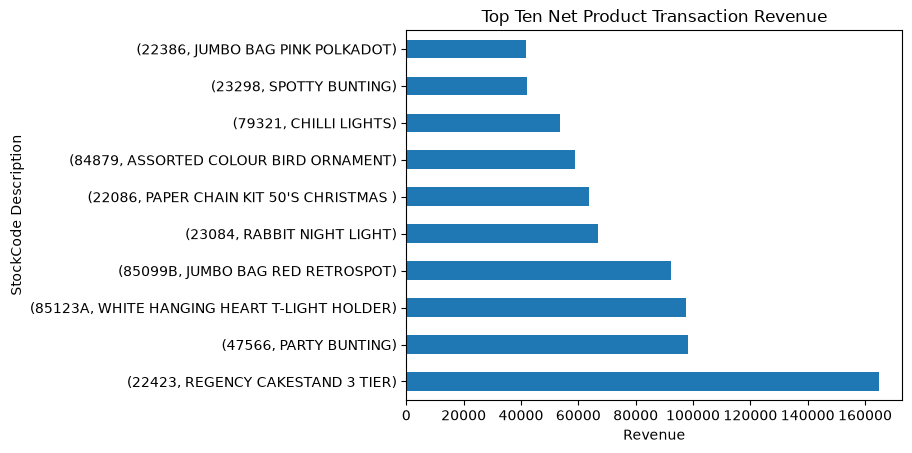

In [191]:
top_10.plot(kind ='barh')
plt.xlabel('Revenue')
plt.ylabel('StockCode Description')
plt.title('Top Ten Net Product Transaction Revenue')
plt.savefig(r'C:\Users\HP\OneDrive\Desktop\portfolios\hbar1')
plt.show()

In [192]:
Retail_ith_cancellation_Mech_N_uk=Retail_ith_cancellation_Mech[~( Retail_ith_cancellation_Mech['Country']=='United Kingdom')].copy()

In [193]:

Top_ten_Country= Retail_ith_cancellation_Mech_N_uk.groupby('Country')['Revenue'].sum().sort_values(ascending = False).head(10)

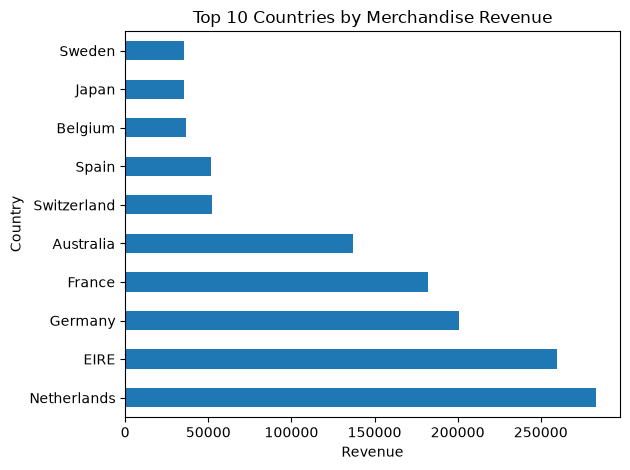

In [194]:
Top_ten_Country.plot(kind ='barh')
plt.xlabel('Revenue')
plt.ylabel('Country')
plt.title('Top 10 Countries by Merchandise Revenue')
plt.tight_layout()
plt.savefig(r'C:\Users\HP\OneDrive\Desktop\portfolios\country.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [195]:
Top_ten_Country

Country
Netherlands    283479.54
EIRE           259663.46
Germany        200808.40
France         182163.39
Australia      136990.00
Switzerland     52505.35
Spain           51765.20
Belgium         36662.96
Japan           35419.79
Sweden          35176.91
Name: Revenue, dtype: float64

In [196]:
Top_ten_customer=Retail_ith_cancellation_Mech.groupby('CustomerID')['Revenue'].sum().sort_values(ascending = False).head(10)

In [197]:
Top_ten_customer

CustomerID
14646.0    278778.02
18102.0    259657.30
17450.0    189735.53
14911.0    128882.13
12415.0    123638.18
14156.0    113855.32
17511.0     88138.20
16684.0     65920.12
13694.0     62924.10
15311.0     59419.34
Name: Revenue, dtype: float64

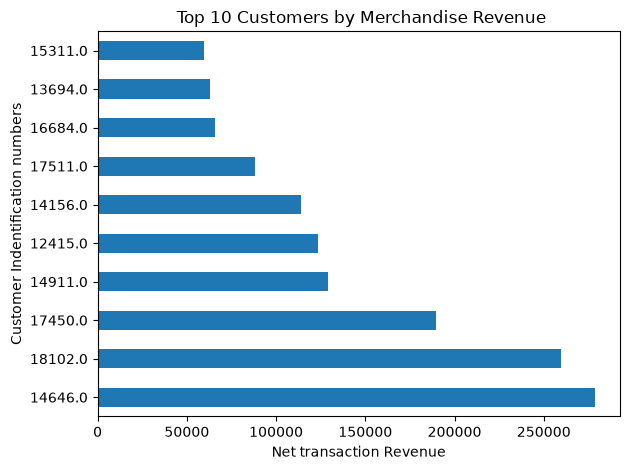

In [198]:
Top_ten_customer.plot(kind='barh')
plt.xlabel('Net transaction Revenue')
plt.ylabel('Customer Indentification numbers')
plt.title(' Top 10 Customers by Merchandise Revenue')
plt.tight_layout()
plt.savefig(r'C:\Users\HP\OneDrive\Desktop\portfolios\customer.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [199]:
valid_ID=Retail_ith_cancellation_Mech[~Retail_ith_cancellation_Mech['CustomerID'].isnull()].copy()

In [200]:
valid_ID['Revenue'].sum()

np.float64(8286663.322999999)

In [201]:
Top_ten_customer=Top_ten_customer.reset_index()

In [202]:
Top_ten_customer['Revenue'].sum()

np.float64(1370948.2400000002)

In [203]:
Top_ten_customer['Revenue'].sum()/valid_ID['Revenue'].sum()

np.float64(0.16544032097875547)

In [204]:
valid_ID['CustomerID'].nunique()

4362

In [205]:
Average_revenue =valid_ID['Revenue'].sum()/ valid_ID['CustomerID'].nunique()

In [206]:
Average_revenue

np.float64(1899.7394138010084)

In [207]:
without_cancellation=valid_ID[~(valid_ID['TransactionType']=='Cancellation')].copy()


In [208]:
without_cancellation['InvoiceNo'].nunique()

18402

In [209]:
without_cancellation['Revenue'].sum()/without_cancellation['InvoiceNo'].nunique()

np.float64(476.0931775350506)

In [210]:
without_cancellation['InvoiceNo'].nunique()/without_cancellation['CustomerID'].nunique()

4.2459621596677435

In [211]:
Customer_order=without_cancellation.groupby('CustomerID')['InvoiceNo'].nunique().sort_values(ascending=False)

In [212]:
Customer_order=Customer_order.reset_index()

In [213]:
Customer_order[ Customer_order['InvoiceNo']>1].shape[0]

2829

In [214]:
Customer_order['InvoiceNo'].shape[0]

4334

In [215]:
Customer_order[ Customer_order['InvoiceNo']>1].shape[0]/Customer_order['InvoiceNo'].shape[0]

0.6527457314259345

In [216]:
valid_transaction_2011=without_cancellation[without_cancellation['Year']==2011]

In [217]:
Valid_data=valid_transaction_2011.groupby('Month')['CustomerID'].nunique()

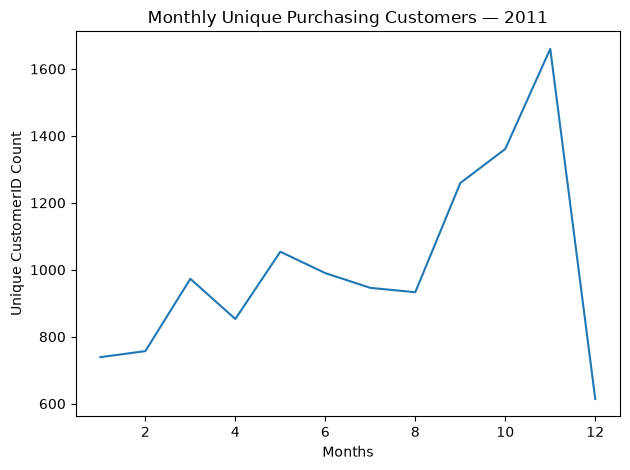

In [218]:
Valid_data.plot(kind = 'line')
plt.xlabel('Months')
plt.ylabel('Unique CustomerID Count')
plt.title('Monthly Unique Purchasing Customers — 2011')
plt.tight_layout()
plt.savefig(r'C:\Users\HP\OneDrive\Desktop\portfolios\customerline.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [219]:
Valid_data

Month
1      739
2      757
3      973
4      853
5     1054
6      990
7      946
8      933
9     1259
10    1361
11    1660
12     614
Name: CustomerID, dtype: int64